# 16. Fundamental 50% Absorption Limit in Coherent Ultrathin Films

## Physical Motivation & Learning Objectives
In an optically thin, symmetric film ($d \ll \lambda$) suspended in free space, coherent wave interference sets a rigorous theoretical bound:
$$A_{\mathrm{max}} = 50\%$$
This maximum occurs when the optical sheet conductance matches the vacuum impedance: $G = 2 / Z_0$.
In this tutorial:
1. We sweep the complex refractive index $(n, \kappa)$ over a 2D parameter space.
2. We map absorption contours and identify the coherent 50% limit.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack


## 2D Complex Index Parameter Sweep


In [2]:
wl = 600.0      # nm
period = 300.0  # nm
film_d = 10.0   # nm (d << lambda)

light = objects.Light(wl, max_order_PWs=0, theta=0.0, phi=0.0)

superstrate = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, loss=False)
substrate   = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, loss=False)
sim_sup = superstrate.calc_modes(light)
sim_sub = substrate.calc_modes(light)

n_vals = np.linspace(0.1, 5.0, 25)
k_vals = np.linspace(0.1, 8.0, 25)
A_grid = np.zeros((len(k_vals), len(n_vals)))

for i, k in enumerate(k_vals):
    for j, n in enumerate(n_vals):
        film = objects.ThinFilm(period, height_nm=film_d, material=materials.Material(complex(n, k)), loss=True)
        sim_film = film.calc_modes(light)
        stk = Stack((sim_sub, sim_film, sim_sup))
        stk.calc_scat(pol='TE')
        A_grid[i, j] = float(stk.a_list[-1])


## 2D Absorption Contour Map


<>:11: SyntaxWarning: "\k" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\k"? A raw string is also an option.
<ipython-input-1-4cea7a922963>:11: SyntaxWarning: "\k" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\k"? A raw string is also an option.
  ax.set_ylabel('Extinction Coefficient $\kappa$', fontsize=11)
<ipython-input-1-4cea7a922963>:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


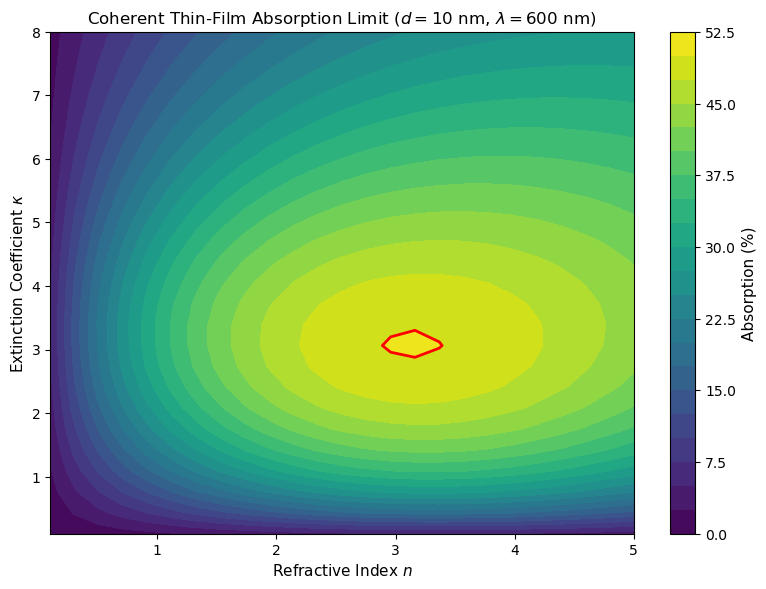

In [3]:
fig, ax = plt.subplots(figsize=(8, 6), dpi=110)
cp = ax.contourf(n_vals, k_vals, A_grid * 100, levels=20, cmap='viridis')
cb = plt.colorbar(cp, ax=ax)
cb.set_label('Absorption (%)', fontsize=11)

# Highlight 50% contour
cs = ax.contour(n_vals, k_vals, A_grid * 100, levels=[50.0], colors='red', linewidths=2)
ax.clabel(cs, inline=True, fmt='50%% Max', fontsize=10)

ax.set_xlabel('Refractive Index $n$', fontsize=11)
ax.set_ylabel('Extinction Coefficient $\kappa$', fontsize=11)
ax.set_title(r'Coherent Thin-Film Absorption Limit ($d = 10$ nm, $\lambda = 600$ nm)', fontsize=12)
plt.tight_layout()
plt.show()


## Physical Interpretation
- Absorption cannot exceed 50% because the symmetric film radiates equally into the forward and backward directions.
- The red contour delineates the optimal $(n, \kappa)$ locus where maximal coherent absorption is achieved.
